Connected to .venv (Python 3.13.2)

# TRENIRANJE XGBOOST MODELA

Evaluacija modela:
MAE (Mean Absolute Error): 1.96
MSE (Mean Squared Error): 7.88
R² (R-squared): 0.92


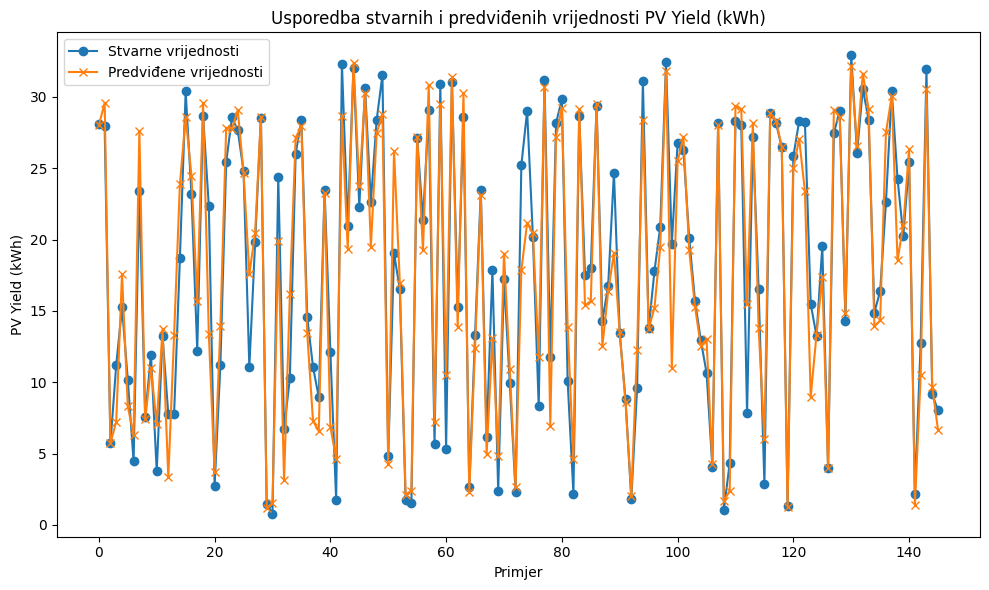

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

# Učitaj podatke
df = pd.read_csv("output/spojeni_podaci.csv")

# Priprema značajki i ciljne varijable
features = ["insolacija", "naoblaka", "temperatura", "Peak Power (kW)"]
target = "PV Yield (kWh)"

# Ukloni redove s nedostajućim vrijednostima u značajkama ili ciljnoj varijabli
df = df[features + [target]].dropna()

# Odvajanje značajki i cilja
X = df[features]
y = df[target]

# Skaliranje podataka
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Podjela na trening i test skup
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Inicijalizacija i treniranje XGBoost modela
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predikcija
y_pred = model.predict(X_test)

# Evaluacija modela
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Evaluacija modela:")
print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"MSE (Mean Squared Error): {mse:.2f}")
print(f"R² (R-squared): {r2:.2f}")

# Vizualizacija stvarnih vs predviđenih vrijednosti
plt.figure(figsize=(10, 6))
plt.plot(y_test.values, label="Stvarne vrijednosti", marker='o')
plt.plot(y_pred, label="Predviđene vrijednosti", marker='x')
plt.title("Usporedba stvarnih i predviđenih vrijednosti PV Yield (kWh)")
plt.xlabel("Primjer")
plt.ylabel("PV Yield (kWh)")
plt.legend()
plt.tight_layout()
plt.savefig("grafovi/XGBoostpredict.png")
plt.show()

## FINE-TUNING

In [23]:
from sklearn.model_selection import GridSearchCV

# Parametri za isprobavanje
param_grid = {
    'n_estimators': [50, 200],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.07, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

# Inicijalizacija modela
xgb_model = xgb.XGBRegressor(random_state=42)

# GridSearch s 3-fold cross-validation
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid,
                           cv=3, scoring='r2', verbose=1, n_jobs=-1)

grid_search.fit(X_train, y_train)

# Najbolji parametri i novi model
print("Najbolji parametri:", grid_search.best_params_)
best_model = grid_search.best_estimator_

# Evaluacija s najboljim modelom
y_pred_best = best_model.predict(X_test)
print("R² s najboljim modelom:", r2_score(y_test, y_pred_best))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Najbolji parametri: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}
R² s najboljim modelom: 0.9352158060428434


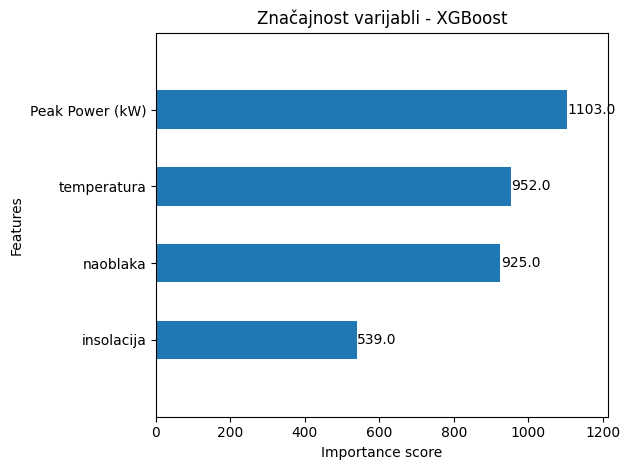

In [24]:
import matplotlib.pyplot as plt
xgb.plot_importance(model, importance_type="weight", show_values=True,
                    xlabel="Importance score", grid=False, height=0.5)
plt.title("Značajnost varijabli - XGBoost")
plt.yticks(ticks=range(len(features)), labels=features)  # koristi tvoju listu features
plt.tight_layout()
plt.savefig("grafovi/XGBoostfeauture_importance.png")
plt.show()